In [1]:
# =============================================================================
# 0. SETUP
# =============================================================================
import ee
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe
from matplotlib.path import Path
from matplotlib.patches import PathPatch
 
ee.Authenticate()
ee.Initialize(project='osmgee')
 
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# =============================================================================
# 1. SETTINGS
# =============================================================================
ASSET   = 'projects/annual-ccdc-new/assets/WaterShed_NTEMS_LandCover_Classes'
OUT_DIR = '/content/drive/MyDrive/NTEMS_Sankey'
TAG     = 'ntems'
 
# Years shown as bars in the diagram (all ~38 years would be unreadable).
# Years not in the asset are dropped automatically in Section 2.
SANKEY_YEARS = [1985, 1990, 1995, 2000, 2005, 2010, 2015, 2020, 2022]
 
# NTEMS classes in the order used by your GEE legend (index 0–12) and their raw codes
CLASS_NAMES_13 = ['Unclassified', 'Water', 'Snow/Ice', 'Rock/Rubble', 'Exposed/Barren land',
                  'Bryoids', 'Shrubs', 'Wetland', 'Wetland-treed', 'Herbs',
                  'Coniferous', 'Broadleaf', 'Mixedwood']
RAW_CODES      = [0, 20, 31, 32, 33, 40, 50, 80, 81, 100, 210, 220, 230]
 
# Classes shown in the diagram, bottom -> top of each bar: (label, [class indices], colour)
# Rare classes are grouped into "Barren/Other" so the diagram stays readable.
# Unclassified (index 0) is left out on purpose.
GROUPS = [
    ('Coniferous',    [10],          '#006600'),
    ('Mixedwood',     [12],          '#cc9900'),
    ('Broadleaf',     [11],          '#00cc00'),
    ('Shrubs',        [6],           '#ffff00'),
    ('Herbs',         [9],           '#ccff33'),
    ('Wetland-treed', [8],           '#9933cc'),
    ('Wetland',       [7],           '#993399'),
    ('Water',         [1],           '#3333ff'),
    ('Barren/Other',  [2, 3, 4, 5],  '#996633'),
]
G = len(GROUPS)
GROUP_NAMES  = [g[0] for g in GROUPS]
GROUP_COLORS = [g[2] for g in GROUPS]
 
import os
os.makedirs(OUT_DIR, exist_ok=True)

In [3]:
# =============================================================================
# 2. LOAD THE ASSET AND CHECK IT
# =============================================================================
watershed_geom = ee.FeatureCollection('projects/osmgee/assets/OSM_Watersheds').geometry()
lc = ee.Image(ASSET)
 
band_names = lc.bandNames().getInfo()
print('Bands in asset:', band_names)
 
proj = lc.select(0).projection().getInfo()
pixel_size = lc.select(0).projection().nominalScale().getInfo()
PIXEL_AREA_KM2 = pixel_size * pixel_size / 1e6
print('CRS:', proj['crs'], '| pixel size (m):', round(pixel_size, 2))
 
 
def band_for(year):
    matches = [b for b in band_names if b.endswith(str(year))]
    return matches[0] if matches else None
 
 
missing = [y for y in SANKEY_YEARS if band_for(y) is None]
SANKEY_YEARS = [y for y in SANKEY_YEARS if band_for(y) is not None]
print('Years used:', SANKEY_YEARS, '| not in asset:', missing or 'none')
 
 
def histogram(img):
    """Pixel count per value inside the watershed, on the asset's own pixel grid."""
    h = img.rename('v').reduceRegion(
        reducer=ee.Reducer.frequencyHistogram(),
        geometry=watershed_geom,
        crs=proj['crs'],
        crsTransform=proj['transform'],
        maxPixels=1e13,
        tileScale=4,
    ).get('v').getInfo()
    return {int(float(k)): v for k, v in (h or {}).items()}
 
 
# Are the values the remapped indices (0–12) or the raw NTEMS codes (20, 31, ...)?
first_hist = histogram(lc.select(band_for(SANKEY_YEARS[0])))
print(f'Values in {SANKEY_YEARS[0]}:', sorted(first_hist))
USES_RAW_CODES = max(first_hist) > 12
print('Asset stores raw NTEMS codes:', USES_RAW_CODES)

Bands in asset: ['LC_1984', 'LC_1985', 'LC_1986', 'LC_1987', 'LC_1988', 'LC_1989', 'LC_1990', 'LC_1991', 'LC_1992', 'LC_1993', 'LC_1994', 'LC_1995', 'LC_1996', 'LC_1997', 'LC_1998', 'LC_1999', 'LC_2000', 'LC_2001', 'LC_2002', 'LC_2003', 'LC_2004', 'LC_2005', 'LC_2006', 'LC_2007', 'LC_2008', 'LC_2009', 'LC_2010', 'LC_2011', 'LC_2012', 'LC_2013', 'LC_2014', 'LC_2015', 'LC_2016', 'LC_2017', 'LC_2018', 'LC_2019', 'LC_2020', 'LC_2021', 'LC_2022']
CRS: EPSG:32612 | pixel size (m): 30
Years used: [1985, 1990, 1995, 2000, 2005, 2010, 2015, 2020, 2022] | not in asset: none
Values in 1985: [1, 4, 6, 7, 8, 9, 10, 11, 12]
Asset stores raw NTEMS codes: False


In [4]:
# =============================================================================
# 3. GROUP THE CLASSES (in GEE)
#    Every class listed in GROUPS gets its group number 0..G-1.
#    Anything not listed (Unclassified) becomes empty and is not counted.
# =============================================================================
source_codes = RAW_CODES if USES_RAW_CODES else list(range(13))
remap_from, remap_to = [], []
for g, (_, idxs, _) in enumerate(GROUPS):
    for i in idxs:
        remap_from.append(source_codes[i])
        remap_to.append(g)
 
 
def grouped(year):
    return lc.select(band_for(year)).remap(remap_from, remap_to)

In [5]:
# =============================================================================
# 4. TRANSITIONS AND AREAS (counted in GEE, one request per pair of years)
#    Each pixel gets the code  (class in year 1) * G + (class in year 2),
#    so one histogram gives the whole from -> to matrix.
# =============================================================================
transitions = {}
for y1, y2 in zip(SANKEY_YEARS[:-1], SANKEY_YEARS[1:]):
    code = grouped(y1).multiply(G).add(grouped(y2))
    counts = np.zeros((G, G))
    for k, n in histogram(code).items():
        counts[k // G, k % G] = n
    transitions[(y1, y2)] = counts * PIXEL_AREA_KM2
    print(f'{y1} -> {y2}: done ({counts.sum() * PIXEL_AREA_KM2:,.1f} km²)')
 
# Bar sizes come from the same matrices, so ribbons and bars always match
areas = {SANKEY_YEARS[0]: transitions[(SANKEY_YEARS[0], SANKEY_YEARS[1])].sum(axis=1)}
for (y1, y2), M in transitions.items():
    areas[y2] = M.sum(axis=0)
 
# ---- Save the numbers -------------------------------------------------------
area_rows = []
for yr in SANKEY_YEARS:
    total = areas[yr].sum()
    row = {'year': yr, 'total_km2': round(total, 2)}
    for g in range(G):
        row[f'{GROUP_NAMES[g]}_km2'] = round(areas[yr][g], 2)
        row[f'{GROUP_NAMES[g]}_pct'] = round(100 * areas[yr][g] / total, 2) if total else 0
    area_rows.append(row)
area_table = pd.DataFrame(area_rows)
print(area_table.to_string(index=False))
area_table.to_csv(f'{OUT_DIR}/class_areas_{TAG}.csv', index=False)
 
for (y1, y2), M in transitions.items():
    pd.DataFrame(M.round(3), index=GROUP_NAMES, columns=GROUP_NAMES).to_csv(
        f'{OUT_DIR}/transitions_{TAG}_{y1}_{y2}.csv')
print('CSVs saved to', OUT_DIR)

1985 -> 1990: done (1,829.6 km²)
1990 -> 1995: done (1,829.6 km²)
1995 -> 2000: done (1,829.6 km²)
2000 -> 2005: done (1,829.6 km²)
2005 -> 2010: done (1,829.6 km²)
2010 -> 2015: done (1,829.6 km²)
2015 -> 2020: done (1,829.6 km²)
2020 -> 2022: done (1,829.6 km²)
 year  total_km2  Coniferous_km2  Coniferous_pct  Mixedwood_km2  Mixedwood_pct  Broadleaf_km2  Broadleaf_pct  Shrubs_km2  Shrubs_pct  Herbs_km2  Herbs_pct  Wetland-treed_km2  Wetland-treed_pct  Wetland_km2  Wetland_pct  Water_km2  Water_pct  Barren/Other_km2  Barren/Other_pct
 1985    1829.57          549.31           30.02          84.01           4.59         130.21           7.12      145.28        7.94      27.00       1.48             533.77              29.17       181.67         9.93     172.11       9.41              6.20              0.34
 1990    1829.57          590.39           32.27          84.55           4.62         134.81           7.37       90.43        4.94      27.05       1.48             563.46         

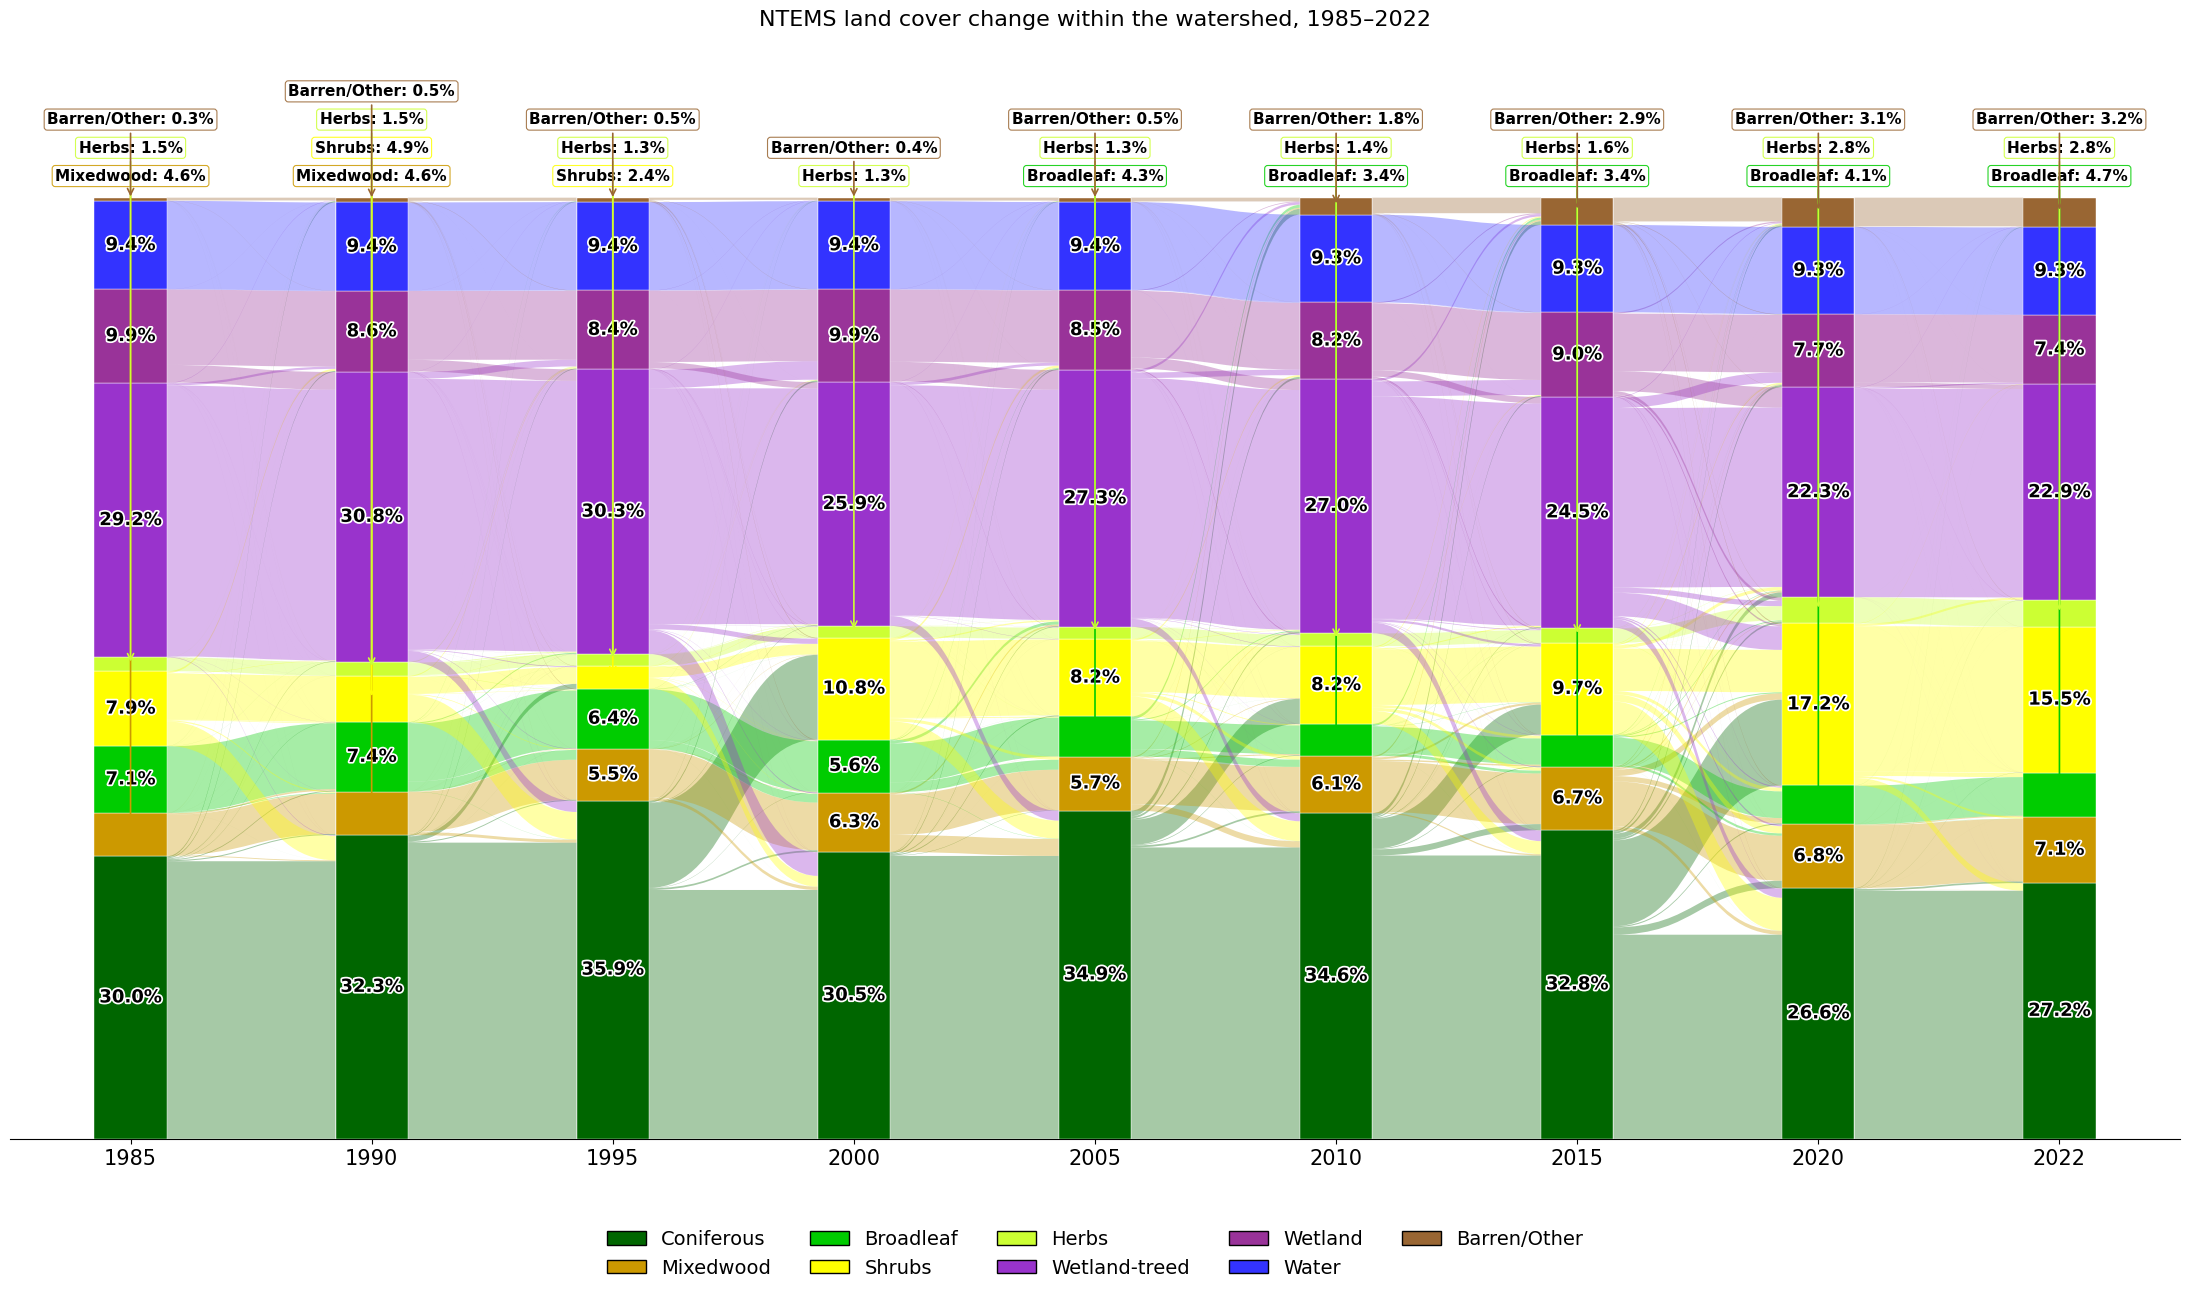

Figure saved to /content/drive/MyDrive/NTEMS_Sankey/sankey_ntems_watershed.png


In [6]:
# =============================================================================
# 5. SANKEY / ALLUVIAL PLOT (same style as the classification scripts)
# =============================================================================
def bezier_patch(ax, x0, x1, y0_bot, y0_top, y1_bot, y1_top, color, alpha=0.35):
    xm = (x0 + x1) / 2
    verts = [(x0, y0_bot), (xm, y0_bot), (xm, y1_bot), (x1, y1_bot),
             (x1, y1_top), (xm, y1_top), (xm, y0_top), (x0, y0_top), (x0, y0_bot)]
    codes = [Path.MOVETO, Path.CURVE4, Path.CURVE4, Path.CURVE4,
             Path.LINETO, Path.CURVE4, Path.CURVE4, Path.CURVE4, Path.CLOSEPOLY]
    ax.add_patch(PathPatch(Path(verts, codes), facecolor=color, alpha=alpha,
                           edgecolor='none', zorder=2))
 
 
def plot_sankey(areas, transitions, names, colors, out_path,
                pct_threshold=5.0, title=None):
    """Bars = class areas per year; ribbons = area moving from one class to another.
    Classes below pct_threshold get a callout label above the bar."""
    years = sorted(areas)
    n = len(names)
    totals = {yr: areas[yr].sum() for yr in years}
    max_total = max(totals.values())
    ann_start, ann_gap = 0.015 * max_total, 0.030 * max_total
    bar_width = 0.3
    xpos = {yr: i for i, yr in enumerate(years)}
 
    fig, ax = plt.subplots(figsize=(22, 13))
    bar_bottoms = {}
    max_small = 0
 
    for yr in years:
        x = xpos[yr]
        bottom = 0.0
        bar_bottoms[yr] = {}
        small = []
        for c in range(n):
            h = areas[yr][c]
            pct = 100 * h / totals[yr] if totals[yr] else 0
            ax.bar(x, h, bottom=bottom, width=bar_width, color=colors[c],
                   edgecolor='white', linewidth=0.3, zorder=3)
            if pct >= pct_threshold:
                txt = ax.text(x, bottom + h / 2, f'{pct:.1f}%', ha='center', va='center',
                              fontsize=13, color='black', fontweight='bold', zorder=4)
                txt.set_path_effects([pe.withStroke(linewidth=2.5, foreground='white')])
            elif h > 0:
                small.append((c, pct, bottom + h / 2))
            bar_bottoms[yr][c] = bottom
            bottom += h
 
        max_small = max(max_small, len(small))
        for i, (c, pct, seg_mid) in enumerate(small):
            ax.annotate(f'{names[c]}: {pct:.1f}%',
                        xy=(x, seg_mid), xytext=(x, bottom + ann_start + i * ann_gap),
                        fontsize=11, color='black', fontweight='bold', ha='center', va='bottom',
                        arrowprops=dict(arrowstyle='->', color=colors[c], lw=1.2),
                        bbox=dict(boxstyle='round,pad=0.2', fc='white', ec=colors[c],
                                  alpha=0.85, linewidth=0.8),
                        annotation_clip=False, zorder=5)
 
    # Ribbons: offsets always advance so tiny flows never shift the stacking
    min_draw = max_total * 1e-5
    for (y1, y2), M in transitions.items():
        x0 = xpos[y1] + bar_width / 2
        x1 = xpos[y2] - bar_width / 2
        src = dict(bar_bottoms[y1])
        dst = dict(bar_bottoms[y2])
        for c1 in range(n):
            for c2 in range(n):
                f = M[c1, c2]
                if f <= 0:
                    continue
                if f >= min_draw:
                    bezier_patch(ax, x0, x1, src[c1], src[c1] + f, dst[c2], dst[c2] + f,
                                 color=colors[c1])
                src[c1] += f
                dst[c2] += f
 
    ax.set_xticks(list(xpos.values()))
    ax.set_xticklabels([str(yr) for yr in years], fontsize=15)
    ax.set_xlim(-0.5, len(years) - 0.5)
    ax.set_yticks([])
    for side in ('top', 'right', 'left'):
        ax.spines[side].set_visible(False)
    ax.set_ylim(0, max_total + ann_start + (max_small + 1) * ann_gap)
    if title:
        ax.set_title(title, fontsize=16, pad=12)
 
    handles = [mpatches.Patch(facecolor=colors[c], edgecolor='black', label=names[c])
               for c in range(n)]
    fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, 0.0),
               ncol=min(n, 5), frameon=False, fontsize=14)
    plt.tight_layout()
    plt.subplots_adjust(bottom=0.12)
    plt.savefig(out_path, dpi=200, bbox_inches='tight')
    plt.show()
 
 
# =============================================================================
# 6. DRAW IT
# =============================================================================
plot_sankey(
    areas, transitions, GROUP_NAMES, GROUP_COLORS,
    out_path=f'{OUT_DIR}/sankey_{TAG}_watershed.png',
    title=f'NTEMS land cover change within the watershed, '
          f'{SANKEY_YEARS[0]}–{SANKEY_YEARS[-1]}',
)
print('Figure saved to', f'{OUT_DIR}/sankey_{TAG}_watershed.png')
 

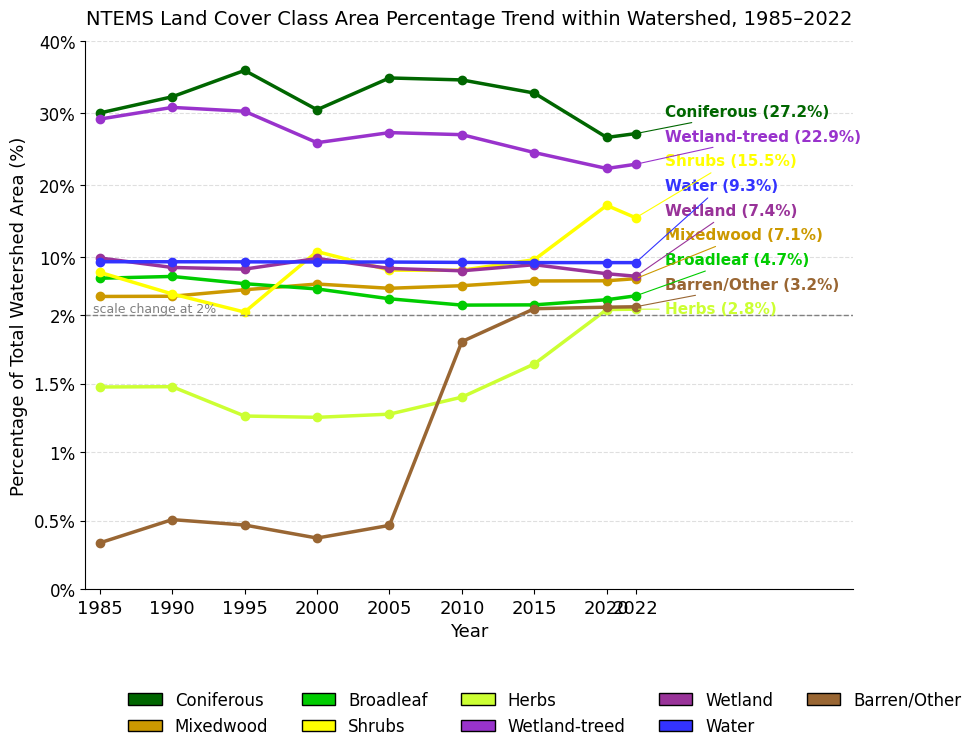

Figure saved to /content/drive/MyDrive/NTEMS_Sankey/trend_ntems_watershed.png


In [7]:
# =============================================================================
# 7. PERCENTAGE TREND GRAPH (same style as the classification scripts)
# =============================================================================
def plot_trend(areas, names, colors, ylabel, title, out_path,
               break_pct=2.0, low_share=0.5):
    """Percentage trend lines. If any class drops below break_pct, the y-axis
    is stretched below that value (piecewise scale) so small classes stay readable."""
    years = sorted(areas)
    n = len(names)
    pcts = {c: [100 * areas[yr][c] / areas[yr].sum() if areas[yr].sum() else 0
                for yr in years] for c in range(n)}

    y_max = min(100.0, np.ceil(max(max(v) for v in pcts.values()) / 10) * 10)
    use_break = min(min(v) for v in pcts.values()) < break_pct

    if use_break:
        def fwd(y):
            y = np.asarray(y, dtype=float)
            return np.where(y <= break_pct, y / break_pct * low_share,
                            low_share + (y - break_pct) / (y_max - break_pct) * (1 - low_share))
        def inv(t):
            t = np.asarray(t, dtype=float)
            return np.where(t <= low_share, t / low_share * break_pct,
                            break_pct + (t - low_share) / (1 - low_share) * (y_max - break_pct))
    else:
        fwd = lambda y: np.asarray(y, dtype=float) / y_max
        inv = lambda t: np.asarray(t, dtype=float) * y_max

    fig, ax = plt.subplots(figsize=(11, 7))
    if use_break:
        ax.set_yscale('function', functions=(fwd, inv))

    for c in range(n):
        ax.plot(years, pcts[c], color=colors[c], linewidth=2.5,
                marker='o', markersize=6, label=names[c])

    if use_break:
        ax.axhline(break_pct, color='grey', linestyle='--', linewidth=1)
        ax.text(years[0] - 0.5, break_pct, f'scale change at {break_pct:g}%',
                fontsize=9, color='grey', va='bottom', ha='left')
        ticks = np.concatenate([np.arange(0, break_pct + 1e-9, break_pct / 4),
                                np.arange(10, y_max + 0.1, 10)])
        ax.set_yticks(ticks)
    else:
        ax.yaxis.set_major_locator(plt.MultipleLocator(10))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:g}%'))
    ax.set_ylim(0, y_max)

    # End-of-line labels, spread so they don't overlap
    MIN_GAP = 0.045
    placed = []
    for c in sorted(range(n), key=lambda c: float(fwd(pcts[c][-1]))):
        t = float(fwd(pcts[c][-1]))
        if placed and t - placed[-1] < MIN_GAP:
            t = placed[-1] + MIN_GAP
        placed.append(t)
        val = pcts[c][-1]
        ax.annotate(f'{names[c]} ({val:.2f}%)' if val < 1 else f'{names[c]} ({val:.1f}%)',
                    xy=(years[-1], val), xytext=(years[-1] + 2, float(inv(t))),
                    textcoords='data', fontsize=11, color=colors[c],
                    va='center', fontweight='bold',
                    arrowprops=dict(arrowstyle='-', color=colors[c], lw=0.8))

    ax.set_xticks(years)
    ax.set_xticklabels([str(yr) for yr in years], fontsize=13)
    ax.set_ylabel(ylabel, fontsize=13)
    ax.set_xlabel('Year', fontsize=13)
    ax.set_title(title, fontsize=14, pad=12)
    ax.set_xlim(years[0] - 1, years[-1] + 15)
    ax.tick_params(axis='y', labelsize=12)
    ax.grid(axis='y', linestyle='--', alpha=0.4)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    handles = [mpatches.Patch(facecolor=colors[c], edgecolor='black', label=names[c])
               for c in range(n)]
    fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, -0.08),
               ncol=min(n, 5), frameon=False, fontsize=12)
    plt.tight_layout()
    plt.subplots_adjust(bottom=0.15, right=0.78)
    plt.savefig(out_path, dpi=200, bbox_inches='tight')
    plt.show()


plot_trend(
    areas, GROUP_NAMES, GROUP_COLORS,
    ylabel='Percentage of Total Watershed Area (%)',
    title=f'NTEMS Land Cover Class Area Percentage Trend within Watershed, '
          f'{SANKEY_YEARS[0]}–{SANKEY_YEARS[-1]}',
    out_path=f'{OUT_DIR}/trend_{TAG}_watershed.png',
)
print('Figure saved to', f'{OUT_DIR}/trend_{TAG}_watershed.png')

 year  total_km2  Forest/Shrub_km2  Forest/Shrub_pct  Wetland_km2  Wetland_pct  Water_km2  Water_pct  Other_km2  Other_pct
 1985    1829.57            908.81             49.67       715.45        39.10     172.11       9.41      33.20       1.81
 1990    1829.57            900.18             49.20       721.01        39.41     172.02       9.40      36.35       1.99
 1995    1829.57            919.14             50.24       706.92        38.64     171.79       9.39      31.71       1.73
 2000    1829.57            974.02             53.24       654.28        35.76     171.46       9.37      29.80       1.63
 2005    1829.57            971.70             53.11       654.62        35.78     171.33       9.36      31.92       1.74
 2010    1829.57            957.05             52.31       643.41        35.17     170.38       9.31      58.72       3.21
 2015    1829.57            963.03             52.64       613.51        33.53     169.94       9.29      83.09       4.54
 2020    1829.57

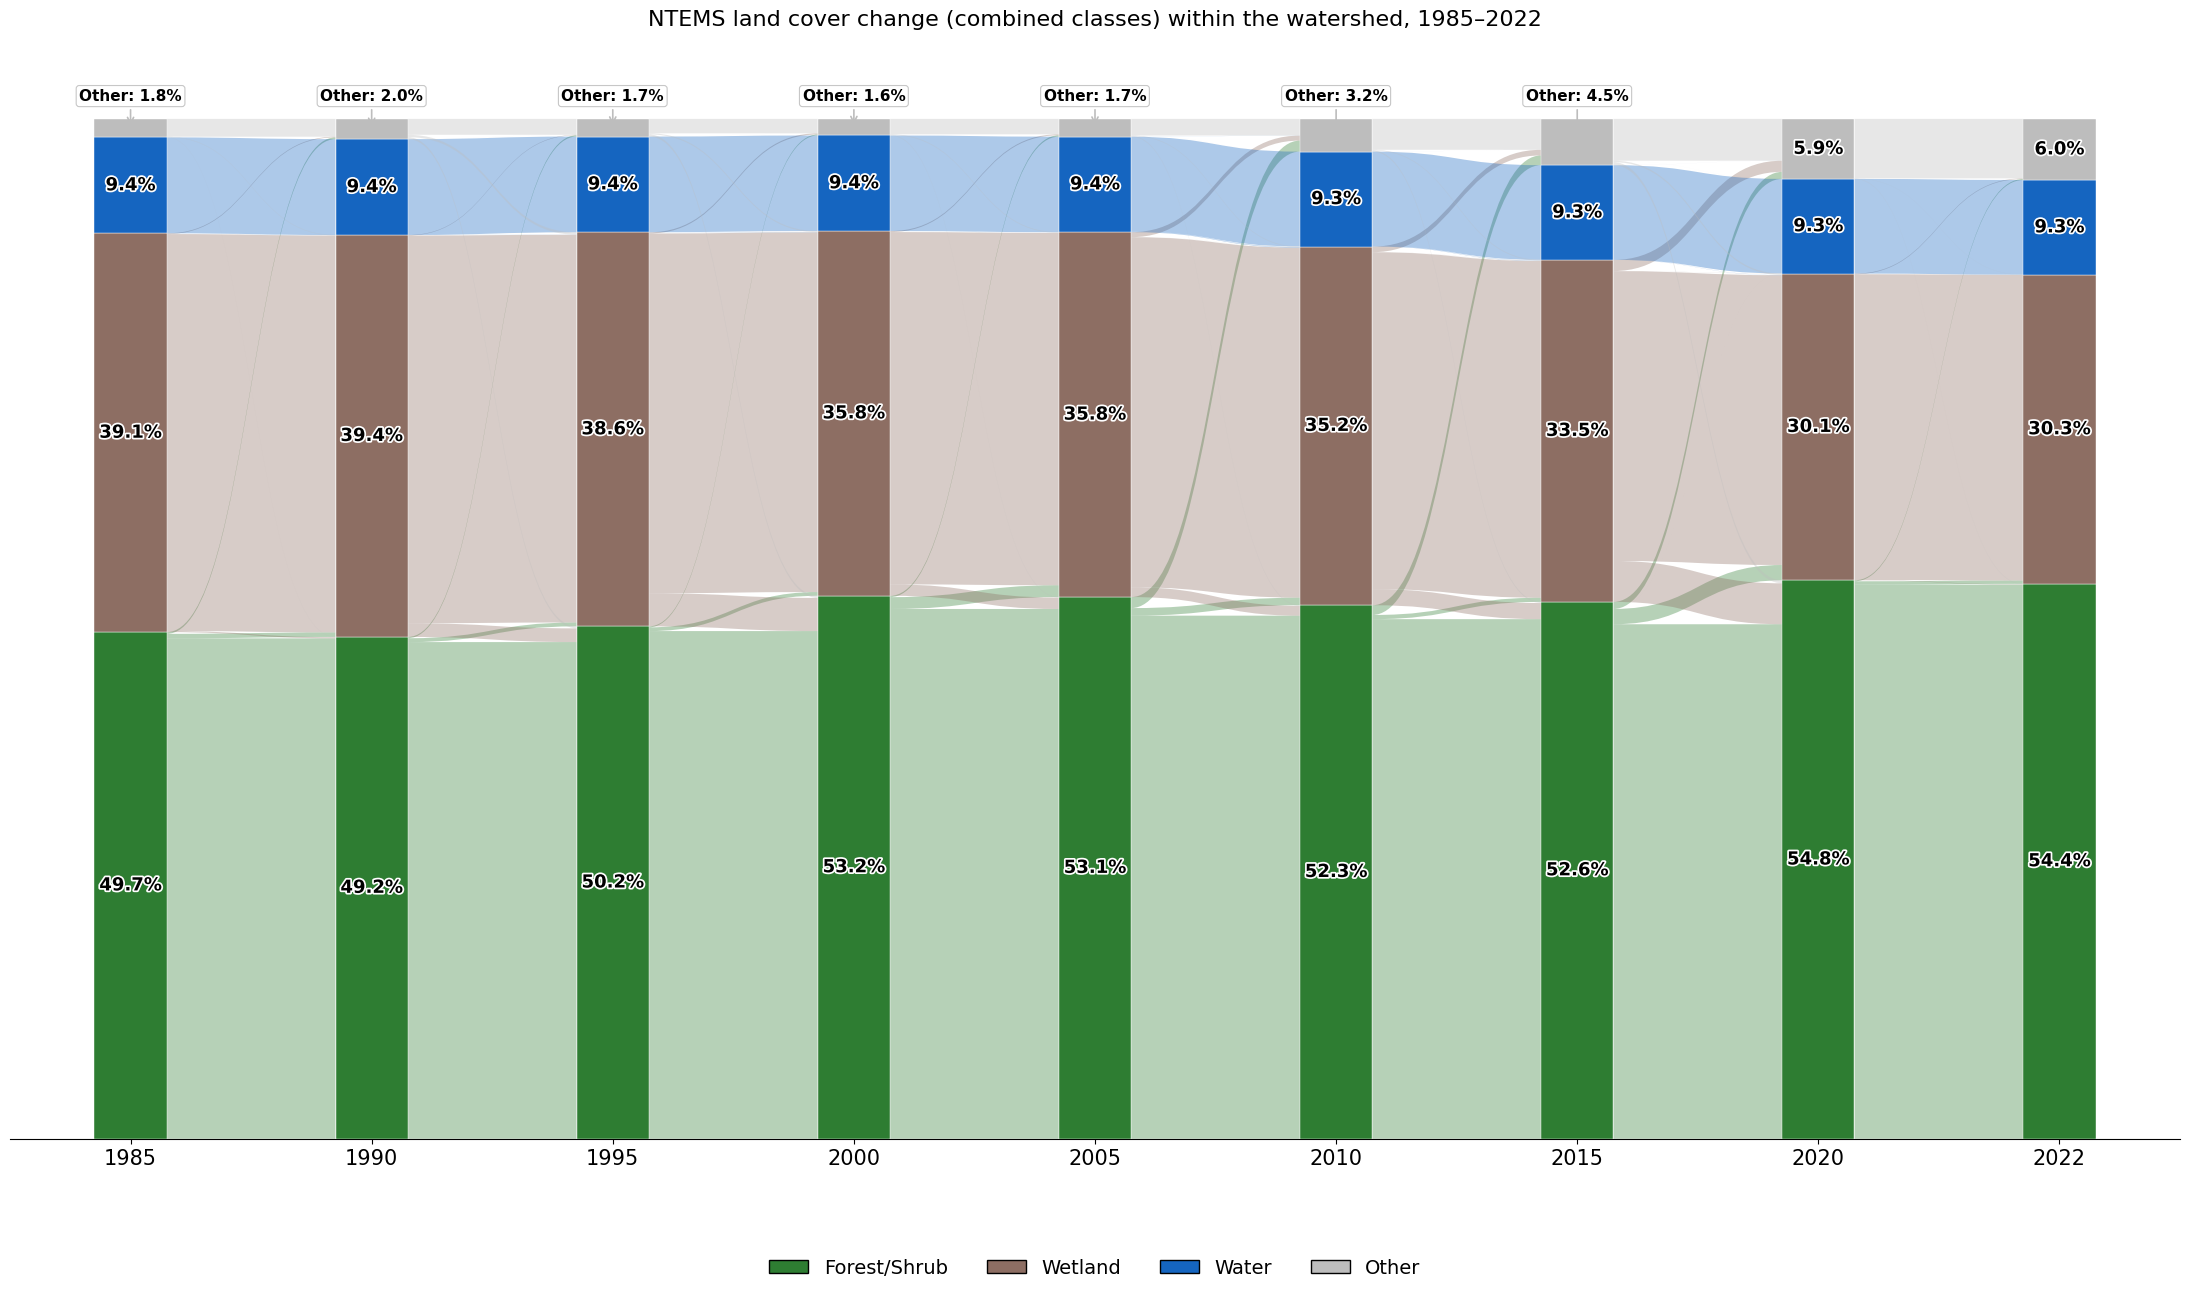

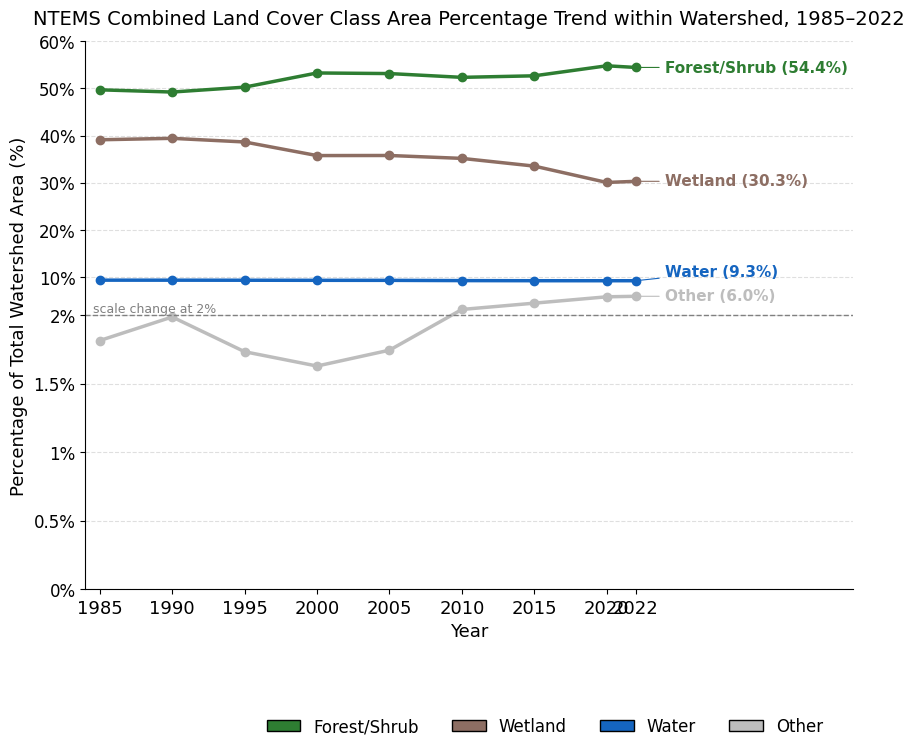

Combined figures and CSVs saved to /content/drive/MyDrive/NTEMS_Sankey


In [8]:
# =============================================================================
# 8. COMBINED CLASSES: Forest/Shrub, Wetland, Water, Other
#    Built from the 9-class results above (no new GEE requests).
#    Grouping follows Hermosilla et al. (2022) class definitions, matched to
#    the ABMI-based 3-class scheme (see methods note).
# =============================================================================
COMBINED = [
    # (new class,    [classes from GROUPS above],                              colour)
    ('Forest/Shrub', ['Coniferous', 'Mixedwood', 'Broadleaf', 'Shrubs'],      '#2E7D32'),
    ('Wetland',      ['Wetland', 'Wetland-treed'],                             '#8D6E63'),
    ('Water',        ['Water'],                                                '#1565C0'),
    ('Other',        ['Herbs', 'Barren/Other'],                                '#BDBDBD'),
]
COMB_NAMES  = [c[0] for c in COMBINED]
COMB_COLORS = [c[2] for c in COMBINED]
K = len(COMBINED)

# ---- Check that every class is used exactly once ---------------------------
listed = [n for _, members, _ in COMBINED for n in members]
unknown = set(listed) - set(GROUP_NAMES)
not_used = set(GROUP_NAMES) - set(listed)
assert not unknown, f'Not in GROUPS: {unknown}'
assert len(listed) == len(set(listed)), 'A class is listed in two combined classes'
if not_used:
    print('WARNING: these classes are left out of the combined graphs:', not_used)

# ---- Membership table: which old class goes into which new class ----------
A = np.zeros((G, K))
for k, (_, members, _) in enumerate(COMBINED):
    for name in members:
        A[GROUP_NAMES.index(name), k] = 1

# ---- Add up areas and transitions -----------------------------------------
areas_comb = {yr: areas[yr] @ A for yr in areas}
transitions_comb = {pair: A.T @ M @ A for pair, M in transitions.items()}

# ---- Save the numbers -------------------------------------------------------
rows = []
for yr in SANKEY_YEARS:
    total = areas_comb[yr].sum()
    row = {'year': yr, 'total_km2': round(total, 2)}
    for k in range(K):
        row[f'{COMB_NAMES[k]}_km2'] = round(areas_comb[yr][k], 2)
        row[f'{COMB_NAMES[k]}_pct'] = round(100 * areas_comb[yr][k] / total, 2) if total else 0
    rows.append(row)
comb_table = pd.DataFrame(rows)
print(comb_table.to_string(index=False))
comb_table.to_csv(f'{OUT_DIR}/class_areas_{TAG}_combined.csv', index=False)

for (y1, y2), M in transitions_comb.items():
    pd.DataFrame(M.round(3), index=COMB_NAMES, columns=COMB_NAMES).to_csv(
        f'{OUT_DIR}/transitions_{TAG}_combined_{y1}_{y2}.csv')


# =============================================================================
# 9. GRAPHS FOR THE COMBINED CLASSES
# =============================================================================
plot_sankey(
    areas_comb, transitions_comb, COMB_NAMES, COMB_COLORS,
    out_path=f'{OUT_DIR}/sankey_{TAG}_combined_watershed.png',
    title=f'NTEMS land cover change (combined classes) within the watershed, '
          f'{SANKEY_YEARS[0]}–{SANKEY_YEARS[-1]}',
)

plot_trend(
    areas_comb, COMB_NAMES, COMB_COLORS,
    ylabel='Percentage of Total Watershed Area (%)',
    title=f'NTEMS Combined Land Cover Class Area Percentage Trend within Watershed, '
          f'{SANKEY_YEARS[0]}–{SANKEY_YEARS[-1]}',
    out_path=f'{OUT_DIR}/trend_{TAG}_combined_watershed.png',
)
print('Combined figures and CSVs saved to', OUT_DIR)